1. Implement the Fourier transform and inverse Fourier transform. Apply your coding to the tested images and show the Fourier spectral images (the transformed images in frequency domain).

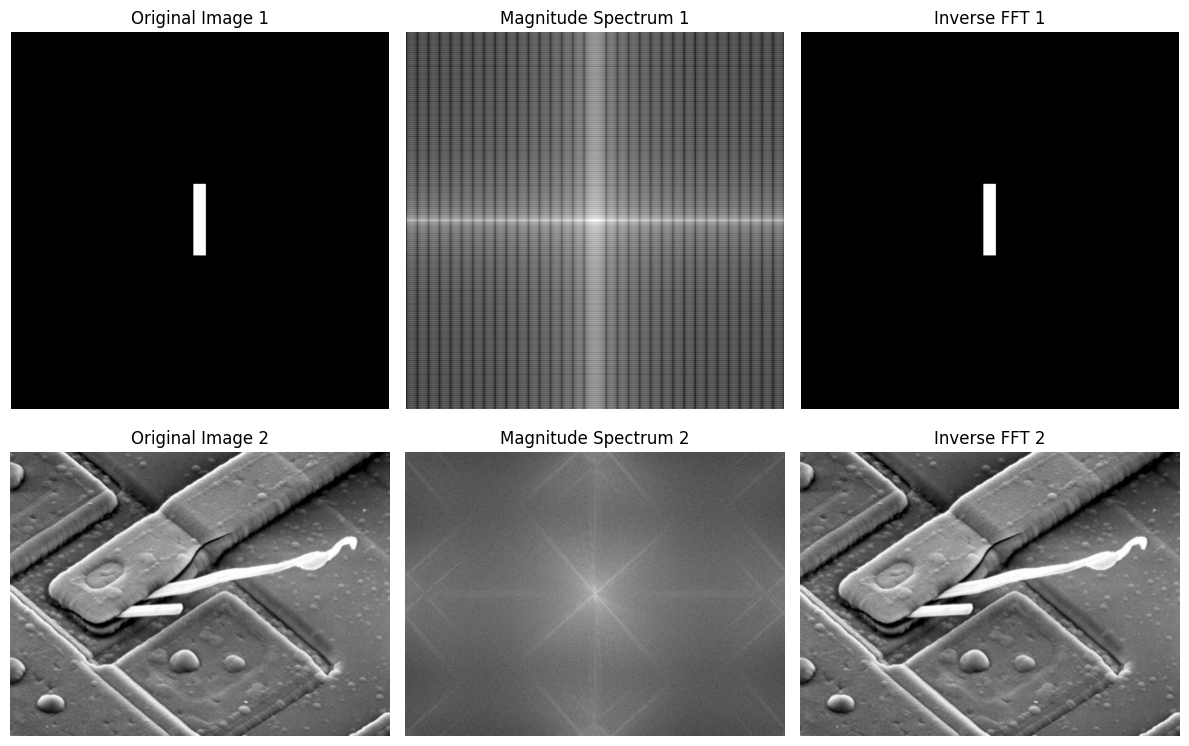

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img1 = cv2.imread('Fig0424(a)(rectangle).bmp', cv2.IMREAD_GRAYSCALE)
img2 = cv2.imread('Fig0429(a)(blown_ic).bmp', cv2.IMREAD_GRAYSCALE)

# === Apply 2D Fourier Transform ===
f1 = np.fft.fft2(img1)
fshift1 = np.fft.fftshift(f1)
f2 = np.fft.fft2(img2)
fshift2 = np.fft.fftshift(f2)

# === Compute magnitude ===
magnitude_spectrum1 = 20 * np.log(np.abs(fshift1) + 1) # use +1 to avoid log 0 and scale 20 for visualization
magnitude_spectrum2 = 20 * np.log(np.abs(fshift2) + 1)

# === Inverse Fourier Transform ===
f_ishift1 = np.fft.ifftshift(fshift1) # shift back
img_reconstructed1 = np.fft.ifft2(f_ishift1) # inverse FFT
img_reconstructed1 = np.abs(img_reconstructed1)
f_ishift2 = np.fft.ifftshift(fshift2)
img_reconstructed2 = np.fft.ifft2(f_ishift2)
img_reconstructed2 = np.abs(img_reconstructed2)

plt.figure(figsize=(12, 8))

plt.subplot(2, 3, 1)
plt.title('Original Image 1')
plt.imshow(img1, cmap='gray')
plt.axis('off')

plt.subplot(2, 3, 2)
plt.title('Magnitude Spectrum 1')
plt.imshow(magnitude_spectrum1, cmap='gray')
plt.axis('off')

plt.subplot(2, 3, 3)
plt.title('Inverse FFT 1')
plt.imshow(img_reconstructed1, cmap='gray')
plt.axis('off')

plt.subplot(2, 3, 4)
plt.title('Original Image 2')
plt.imshow(img2, cmap='gray')
plt.axis('off')

plt.subplot(2, 3, 5)
plt.title('Magnitude Spectrum 2')
plt.imshow(magnitude_spectrum2, cmap='gray')
plt.axis('off')

plt.subplot(2, 3, 6)
plt.title('Inverse FFT 2')
plt.imshow(img_reconstructed2, cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.show()


2. Filter the tested images using ideal lowpass and highpass filters with cutoff frequency=5 and 30. Show the filtering results and the kernel functions you used.

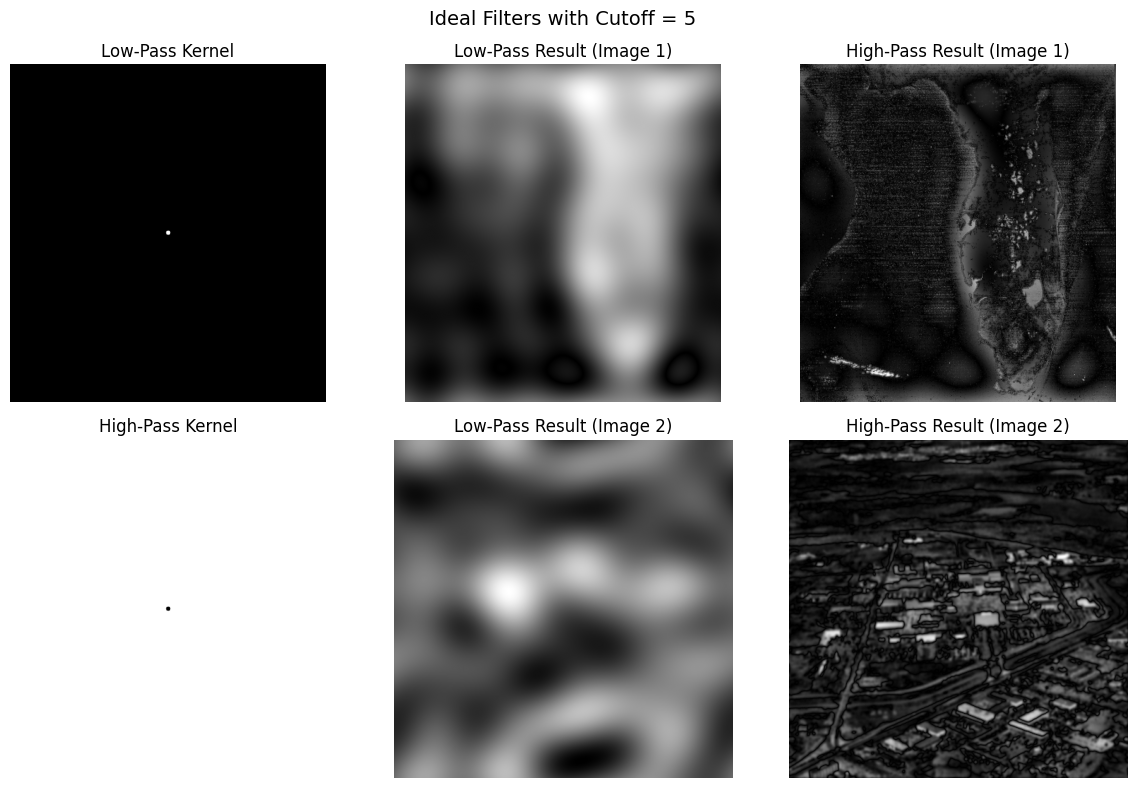

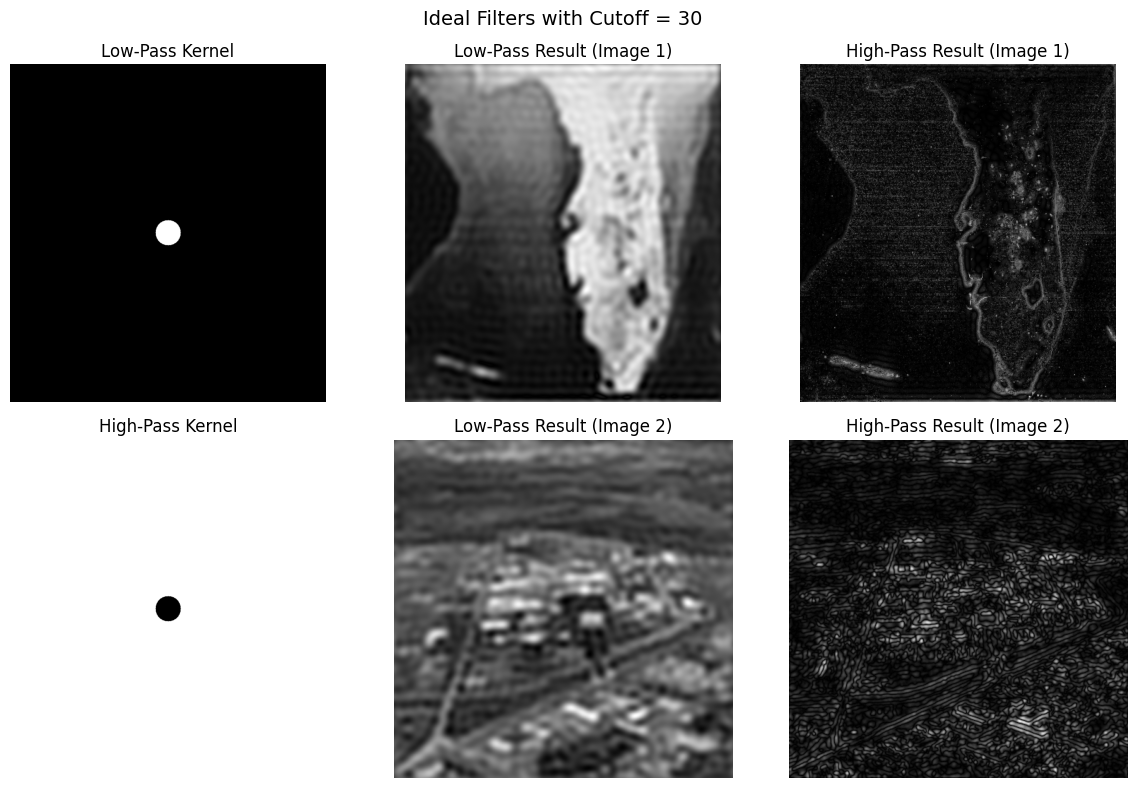

In [2]:
img1 = cv2.imread('Fig0519(a)(florida_satellite_original).bmp', cv2.IMREAD_GRAYSCALE)
img2 = cv2.imread('Fig0525(c)(aerial_view_turb_c_0pt001).bmp', cv2.IMREAD_GRAYSCALE)

# === Define a function to create ideal filters ===
def ideal_filter(shape, cutoff, highpass=False):
    rows, cols = shape
    crow, ccol = rows // 2, cols // 2  # center
    mask = np.zeros((rows, cols), np.uint8)
    for u in range(rows):
        for v in range(cols):
            D = np.sqrt((u - crow)**2 + (v - ccol)**2) # calculate the distance to the center
            if highpass:
                mask[u, v] = 0 if D <= cutoff else 1 # if high pass filter, D<= cutoff is 0, else is 1
            else:
                mask[u, v] = 1 if D <= cutoff else 0 # low pass filter is inverse high pass filter
    return mask

# === Define filtering function ===
def apply_filter(img, cutoff, highpass=False):
    f = np.fft.fft2(img)
    fshift = np.fft.fftshift(f)

    # create filter mask
    mask = ideal_filter(img.shape, cutoff, highpass)
    fshift_filtered = fshift * mask # apply the filter

    # inverse transform
    f_ishift = np.fft.ifftshift(fshift_filtered)
    img_filtered = np.abs(np.fft.ifft2(f_ishift))
    return img_filtered, mask

# === Apply filters ===
cutoffs = [5, 30]
results = []

for cutoff in cutoffs:
    # low-pass
    filtered1_lp, mask_lp = apply_filter(img1, cutoff, highpass=False)
    filtered2_lp, _ = apply_filter(img2, cutoff, highpass=False) # we don't need to get the other mask_lp
    # high-pass
    filtered1_hp, mask_hp = apply_filter(img1, cutoff, highpass=True)
    filtered2_hp, _ = apply_filter(img2, cutoff, highpass=True)
    results.append((cutoff, mask_lp, mask_hp, filtered1_lp, filtered1_hp, filtered2_lp, filtered2_hp))

for cutoff, mask_lp, mask_hp, f1_lp, f1_hp, f2_lp, f2_hp in results:
    plt.figure(figsize=(12, 8))
    plt.suptitle(f"Ideal Filters with Cutoff = {cutoff}", fontsize=14)

    plt.subplot(2, 3, 1)
    plt.title('Low-Pass Kernel')
    plt.imshow(mask_lp, cmap='gray')
    plt.axis('off')

    plt.subplot(2, 3, 4)
    plt.title('High-Pass Kernel')
    plt.imshow(mask_hp, cmap='gray')
    plt.axis('off')

    plt.subplot(2, 3, 2)
    plt.title('Low-Pass Result (Image 1)')
    plt.imshow(f1_lp, cmap='gray')
    plt.axis('off')

    plt.subplot(2, 3, 3)
    plt.title('High-Pass Result (Image 1)')
    plt.imshow(f1_hp, cmap='gray')
    plt.axis('off')

    plt.subplot(2, 3, 5)
    plt.title('Low-Pass Result (Image 2)')
    plt.imshow(f2_lp, cmap='gray')
    plt.axis('off')

    plt.subplot(2, 3, 6)
    plt.title('High-Pass Result (Image 2)')
    plt.imshow(f2_hp, cmap='gray')
    plt.axis('off')

    plt.tight_layout()
    plt.show()
